<a href="https://colab.research.google.com/github/MelB18/EasyQuanten/blob/main/PageWootters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Statisches Gesamtuniversum

In [ ]:
!pip install 'qiskit[visualization]'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 10.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 14.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit]


## Simulation mit 2 Qubits

Qubit 0 übernimmt die Rolle der Uhr, Qubit 1 repräsentiert das System (den Rest der Welt)

Gemeinsam erzeugen sie eine History-State-Superposition

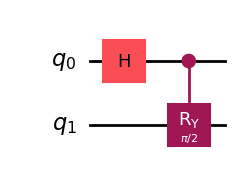

In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# 1. Schaltkreis für das "statische Gesamtuniversum" (Qubit 0 = Uhr, Qubit 1 = System)
qc = QuantumCircuit(2)

# Schritt A: Die Uhr in eine Überlagerung aus t=0 (|0>) und t=1 (|1>) bringen
qc.h(0)

# Schritt B: Kontrollierte Zeitentwicklung (CRy-Gatter)
# Wenn Uhr = |0> (t=0): System bleibt im Zustand |0>
# Wenn Uhr = |1> (t=1): System wird um Winkel theta gedreht
theta = np.pi / 2
qc.cry(theta, control_qubit=0, target_qubit=1)

qc.draw('mpl')



### Erzeugung der Verschränkung (h + cry):
Das Hadamard-Gatter (h) erzeugt die Zeitpunkte t=0 und t=1 gleichzeitig. Das kontrollierte Rotationsgatter (cry) verknüpft jeden Uhr-Zustand mit dem passenden Entwicklungsstadium des Systems.

### Externe Sicht (universe_state):
Der Vektor universe_state ändert sich nicht – er kodiert die gesamte Geschichte des Mini-Universums auf einmal.



In [ ]:
# Den zeitlosen Gesamtzustand |Psi> berechnen
universe_state = Statevector.from_instruction(qc)
print(universe_state)

Statevector([0.70710678+0.j, 0.5       +0.j, 0.        +0.j,
             0.5       +0.j],
            dims=(2, 2))


### Erklärung des `universe_state` (Statevector)

Der Rückgabewert `universe_state` ist ein Objekt der Klasse `Statevector` aus Qiskit. Er repräsentiert den quantenmechanischen Zustand des gesamten 2-Qubit-Systems als Vektor im Hilbertraum.

#### 1. Die mathematische Struktur (Vektordarstellung)
Im Code wird der Vektor wie folgt ausgegeben:
`Statevector([0.70710678+0.j, 0.5+0.j, 0.+0.j, 0.5+0.j], dims=(2, 2))`

Dies entspricht einem 4-dimensionalen komplexen Vektor (da $2^2 = 4$ mögliche Basiszustände für 2 Qubits existieren):

$$\vert\Psi\rangle = \begin{pmatrix} c_{00} \\ c_{01} \\ c_{10} \\ c_{11} \end{pmatrix} = \begin{pmatrix} 0.707 \\ 0.500 \\ 0.000 \\ 0.500 \end{pmatrix}$$

Die komplexen Zahlen (z. B. `0.70710678+0.j`) sind die **Wahrscheinlichkeitsamplituden** für die jeweiligen Basiszustände. Das Quadrat des Betrags einer Amplitude $|c_i|^2$ gibt die Wahrscheinlichkeit an, diesen Zustand bei einer Messung zu finden.

#### 2. Die Zuordnung der Zustände (Qiskit-Reihenfolge)
In Qiskit wird die Bit-Reihenfolge (Endianness) von rechts nach links gelesen:
* **Rechtes Bit (Index 0):** Qubit 0 (unsere Uhr)
* **Linkes Bit (Index 1):** Qubit 1 (unser System)

Die 4 Einträge im Vektor entsprechen standardmäßig den Binärzuständen in aufsteigender Reihenfolge ($00_2, 01_2, 10_2, 11_2$):

1. **Index 0 (`00`):** $\vert\text{System}=0, \text{Uhr}=0\rangle \rightarrow$ Amplitude $\approx 0.707$ (oder $\frac{1}{\sqrt{2}}$)
2. **Index 1 (`01`):** $\vert\text{System}=0, \text{Uhr}=1\rangle \rightarrow$ Amplitude $= 0.5$
3. **Index 2 (`10`):** $\vert\text{System}=1, \text{Uhr}=0\rangle \rightarrow$ Amplitude $= 0.0$
4. **Index 3 (`11`):** $\vert\text{System}=1, \text{Uhr}=1\rangle \rightarrow$ Amplitude $= 0.5$

#### 3. Physikalische Interpretation des Gesamtzustands
Zusammengesetzt lautet der zeitlose Zustand unseres Universums:

$$\vert\Psi\rangle = \frac{1}{\sqrt{2}}\vert00\rangle + \frac{1}{2}\vert01\rangle + \frac{1}{2}\vert11\rangle$$

* **$\vert00\rangle$ (Uhr zeigt $0$, System ist $0$):** Da die Amplitude $\frac{1}{\sqrt{2}}$ ist, beträgt die Wahrscheinlichkeit hierfür $|\frac{1}{\sqrt{2}}|^2 = 0.5$ ($50\%$).
* **$\vert01\rangle$ (Uhr zeigt $1$, System ist $0$):** Wahrscheinlichkeit $= |0.5|^2 = 0.25$ ($25\%$).
* **$\vert11\rangle$ (Uhr zeigt $1$, System ist $1$):** Wahrscheinlichkeit $= |0.5|^2 = 0.25$ ($25\%$).
* Der Zustand $\vert10\rangle$ (Uhr zeigt $0$, System ist $1$) hat die Amplitude $0$ und kann daher niemals gemessen werden (Wahrscheinlichkeit $= 0\%$).

## Simulation mit 4 Qubits

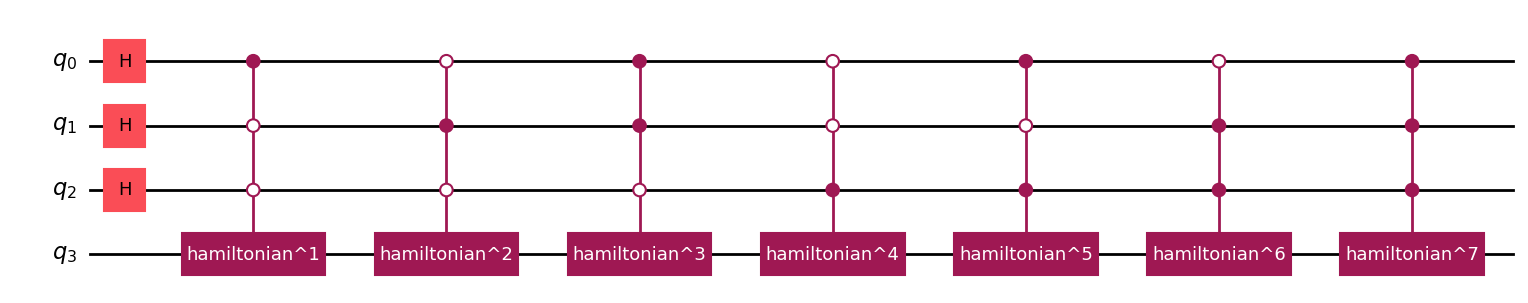

In [ ]:
from qiskit.circuit.library.generalized_gates import unitary
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import HamiltonianGate
from qiskit.quantum_info import SparsePauliOp, Statevector

# --- 1. PARAMETER & HAMILTON-OPERATOR ---
n_clock = 3                  # 3 Uhr-Qubits -> 2^3 = 8 Zeitschritte (t = 0..7)
n_steps = 2**n_clock
dt = 0.25                    # Zeitabstand zwischen zwei Takten
omega = 1.0                  # Energie-Skala des Systems

# Physikalischer Hamilton-Operator: H = omega * X (erzeugt Rabi-Oszillationen)
H = SparsePauliOp("X", coeffs=[omega])

# Zeitentwicklungs-Gatter U(dt) = exp(-i * H * dt) für genau EINEN Zeitschritt
U_step = HamiltonianGate(H, time=dt, label="U(dt)")

# --- 2. ZEITLOSEN HISTORY-STATE ERZEUGEN ---
# Qubits 0, 1, 2 = Uhr | Qubit 3 = System (Rest des Universums)
qc = QuantumCircuit(n_clock + 1)

# Alle 8 Zeitpunkte in gleichmäßige Superposition bringen
qc.h(range(n_clock))

# Für jeden Zeitpunkt t (0 bis 7) das System t-mal mit U(dt) entwickeln
for t in range(n_steps):
    if t == 0:
          continue  # Bei t=0 bleibt das System im Anfangszustand |0>

    # Binärdarstellung von t (z.B. t=3 -> '011'), passend zu Qiskit-Bitreihenfolge
    ctrl_state = format(t, f"0{n_clock}b")

    # Mehrfach kontrolliertes Gatter: Wenn Uhr == t, wende U(dt)^t auf System an
    U_t = U_step.power(t)
    controlled_U_t = U_t.control(num_ctrl_qubits=n_clock, ctrl_state=ctrl_state)
    qc.append(controlled_U_t, list(range(n_clock)) + [n_clock])

qc.draw('mpl')


In [ ]:
# Der gesamte zeitlose Zustand |Psi> des Universums
universe_state = Statevector.from_instruction(qc)
print(universe_state)

Statevector([ 3.53553391e-01+3.06143999e-14j,
              3.42562272e-01+3.45001805e-14j,
              3.10272290e-01+2.72837308e-14j,
              2.58691080e-01+1.70141679e-14j,
              1.91025712e-01+1.63966063e-14j,
              1.11483290e-01+9.60733229e-15j,
              2.50093775e-02-1.68615122e-15j,
             -6.30194973e-02-6.74070175e-15j,
              1.28369537e-15+6.62664368e-16j,
              1.29896094e-14-8.74705086e-02j,
              1.67504899e-14-1.69502525e-01j,
              1.83880688e-14-2.40995695e-01j,
              2.48551180e-14-2.97504920e-01j,
              3.62349040e-14-3.35516730e-01j,
              2.98372438e-14-3.52667735e-01j,
              2.40640841e-14-3.47891568e-01j],
            dims=(2, 2, 2, 2))


### Erklärung des erweiterten `universe_state` (4 Qubits)

Im erweiterten Code haben wir ein System mit insgesamt **4 Qubits**:
* **3 Uhr-Qubits** (Qubits 0, 1 und 2) $\rightarrow$ ermöglichen $2^3 = 8$ Zeitschritte (von $t = 0$ bis $t = 7$).
* **1 System-Qubit** (Qubit 3) $\rightarrow$ das physikalische System, das sich im Laufe der Zeit verändert.

Da $2^4 = 16$ mögliche Basiszustände existieren, besitzt dieser `Statevector` genau **16 komplexe Amplituden**.

---

#### 1. Die Bit-Reihenfolge in Qiskit (Endianness)
In Qiskit wird die Bit-Reihenfolge von rechts nach links gelesen:

$$\vert q_3 \quad q_2 \, q_1 \, q_0 \rangle = \vert \text{System} \quad \text{Uhr}_2 \, \text{Uhr}_1 \, \text{Uhr}_0 \rangle$$

* **Die rechten 3 Bits** bilden zusammen den Binärwert der Uhr ($t$).
* **Das linke Bit** stellt den Zustand des Systems dar ($0$ oder $1$).

#### 2. Struktur der 16 Einträge im Vektor
Der Vektor ist in zwei Blöcke zu je 8 Einträgen unterteilt:

* **Die ersten 8 Amplituden (Index 0 bis 7):**
  Hier ist das System im Zustand $\vert 0 \rangle$ (das linke Bit $q_3$ ist `0`).
  $$\vert 0 \underbrace{000}_{t=0} \rangle, \quad \vert 0 \underbrace{001}_{t=1} \rangle, \quad \dots, \quad \vert 0 \underbrace{111}_{t=7} \rangle$$

* **Die letzten 8 Amplituden (Index 8 bis 15):**
  Hier ist das System im Zustand $\vert 1 \rangle$ (das linke Bit $q_3$ ist `1`).
  $$\vert 1 \underbrace{000}_{t=0} \rangle, \quad \vert 1 \underbrace{001}_{t=1} \rangle, \quad \dots, \quad \vert 1 \underbrace{111}_{t=7} \rangle$$

---

#### 3. Physikalische Interpretation eines Beispiels
Schauen wir uns den Zeitpunkt $t = 3$ (binär `011`) an:

* Die Amplitude für den Zustand $\vert \text{System}=0, \text{Uhr}=3 \rangle$, also $\vert 0011 \rangle$ (Index 3), ist:
  $$c_3 \approx 0.2587 + 0i$$
* Die Amplitude für den Zustand $\vert \text{System}=1, \text{Uhr}=3 \rangle$, also $\vert 1011 \rangle$ (Index $8 + 3 = 11$), ist:
  $$c_{11} \approx 0 - 0.241i$$

Wenn wir nun die Uhr ablesen und diese den Wert $t = 3$ zeigt, befindet sich das System in einer Superposition aus $\vert0\rangle$ und $\vert1\rangle$. Die relativen Wahrscheinlichkeiten betragen:
* $P(\text{System}=0 \mid t=3) \propto |c_3|^2 = 0.2587^2 \approx 0.067$
* $P(\text{System}=1 \mid t=3) \propto |c_{11}|^2 = |-0.241|^2 \approx 0.058$

Normiert man diese bedingten Wahrscheinlichkeiten, erhält man die dynamische Entwicklung des Systems (Rabi-Oszillationen) zu genau diesem Zeitpunkt.

### Was ist die Rabi-Oszillation?

Eine **Rabi-Oszillation** beschreibt das periodische Hin- und Herwechseln eines quantenmechanischen Zwei-Niveau-Systems (z. B. unser System-Qubit) zwischen seinen beiden Basiszuständen $\vert 0 \rangle$ und $\vert 1 \rangle$ unter dem Einfluss eines externen Störfelds (im Code repräsentiert durch den Hamilton-Operator $H = \omega X$).

* **Zustand $\vert 0 \rangle$:** Der Grundzustand.
* **Zustand $\vert 1 \rangle$:** Der angeregte Zustand.
* **Der Prozess:** Da der Hamilton-Operator proportional zu $X$ (dem Pauli-X-Gatter, also einem Quanten-NOT) ist, „rotiert“ der Zustand des Systems kontinuierlich. Nach einer bestimmten Zeit ist das System komplett im Zustand $\vert 1 \rangle$, schwingt danach wieder zurück zu $\vert 0 \rangle$ und so weiter.

---

### Wie normiert man die bedingten Wahrscheinlichkeiten?

Da der Gesamtzustand $\vert\Psi\rangle$ ein verschränkter Zustand aller Zeitpunkte ist, ist die Wahrscheinlichkeit, das System in einem bestimmten Zustand zu finden, *abhängig* (bedingt) von dem Zustand, den wir an der Uhr ablesen ($t$).

Laut der Wahrscheinlichkeitstheorie ist die bedingte Wahrscheinlichkeit $P(A \mid B)$ definiert als:

$$P(\text{System} = s \mid \text{Uhr} = t) = \frac{P(\text{System} = s \cap \text{Uhr} = t)}{P(\text{Uhr} = t)}$$

#### Schritt-für-Schritt-Normierung:

1. **Gemeinsame Wahrscheinlichkeiten bestimmen:**
   Wir berechnen die Quadrate der Amplituden für einen festen Zeitpunkt $t$.
   * $P(\text{System} = 0 \cap \text{Uhr} = t) = |c_{0, t}|^2$ (Amplitude im ersten Block)
   * $P(\text{System} = 1 \cap \text{Uhr} = t) = |c_{1, t}|^2$ (Amplitude im zweiten Block)

2. **Die Gesamtwahrscheinlichkeit der Uhr für den Zeitpunkt $t$ berechnen:**
   Das ist die Summe der beiden Wahrscheinlichkeiten (da das System nur $0$ oder $1$ sein kann):
   $$P(\text{Uhr} = t) = |c_{0, t}|^2 + |c_{1, t}|^2$$

3. **Die Normierung (Bedingte Wahrscheinlichkeit):**
   Damit die Wahrscheinlichkeiten für das System zum Zeitpunkt $t$ wieder in Summe genau $1$ ($100\%$) ergeben, teilen wir die Einzelwahrscheinlichkeiten durch $P(\text{Uhr} = t)$:

   $$P(\text{System} = 0 \mid \text{Uhr} = t) = \frac{|c_{0, t}|^2}{|c_{0, t}|^2 + |c_{1, t}|^2}$$
   $$P(\text{System} = 1 \mid \text{Uhr} = t) = \frac{|c_{1, t}|^2}{|c_{0, t}|^2 + |c_{1, t}|^2}$$

### Visualisierung der Rabi-Oszillation

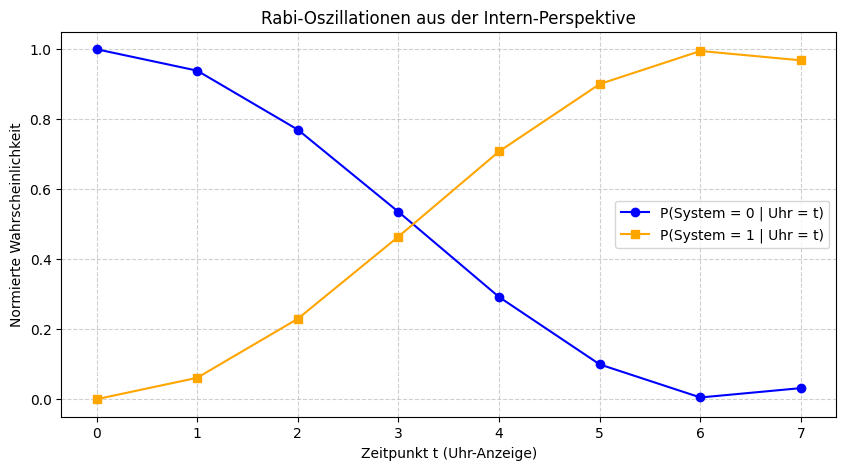

In [ ]:
import matplotlib.pyplot as plt

# Arrays für die normierten Wahrscheinlichkeiten vorbereiten
t_values = list(range(n_steps))
p_sys0 = []
p_sys1 = []

# Amplituden-Dictionary des universe_state holen
amps = universe_state.data

for t in range(n_steps):
    # Index für System=0 und Uhr=t
    idx_0 = t
    # Index für System=1 und Uhr=t
    idx_1 = n_steps + t

    # Wahrscheinlichkeiten (Quadrat der Beträge der Amplituden)
    prob_0_and_t = np.abs(amps[idx_0])**2
    prob_1_and_t = np.abs(amps[idx_1])**2

    # Normierungsfaktor: P(Uhr = t)
    p_u_t = prob_0_and_t + prob_1_and_t

    # Normierte (bedingte) Wahrscheinlichkeiten berechnen
    p_sys0.append(prob_0_and_t / p_u_t)
    p_sys1.append(prob_1_and_t / p_u_t)

# Visualisierung der Rabi-Oszillation über die Zeitpunkte t
plt.figure(figsize=(10, 5))
plt.plot(t_values, p_sys0, 'o-', label="P(System = 0 | Uhr = t)", color='blue')
plt.plot(t_values, p_sys1, 's-', label="P(System = 1 | Uhr = t)", color='orange')
plt.xlabel("Zeitpunkt t (Uhr-Anzeige)")
plt.ylabel("Normierte Wahrscheinlichkeit")
plt.title("Rabi-Oszillationen aus der Intern-Perspektive")
plt.xticks(t_values)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## Quantensimulation mit 3 Uhr-Qubits und 2 System-Qubits

Wir erweitern unser Universum auf **5 Qubits**:
* **Qubits 0, 1, 2:** Die Uhr ($2^3 = 8$ Zeitschritte, $t = 0..7$)
* **Qubits 3, 4:** Das System aus zwei Qubits.

#### Die Dynamik:
Über die Zeit $t$ hinweg lassen wir das System eine Verschränkung aufbauen.
* Bei $t=0$ startet das System im Zustand $|00\rangle$.
* Über kontrollierte Rotationen ($R_y$) und kontrollierte CNOT-Gatter transformieren wir das System schrittweise. Am Ende des Zyklus ($t=7$) steuern wir das System so an, dass es sich einem verschränkten Bell-Zustand nähert.

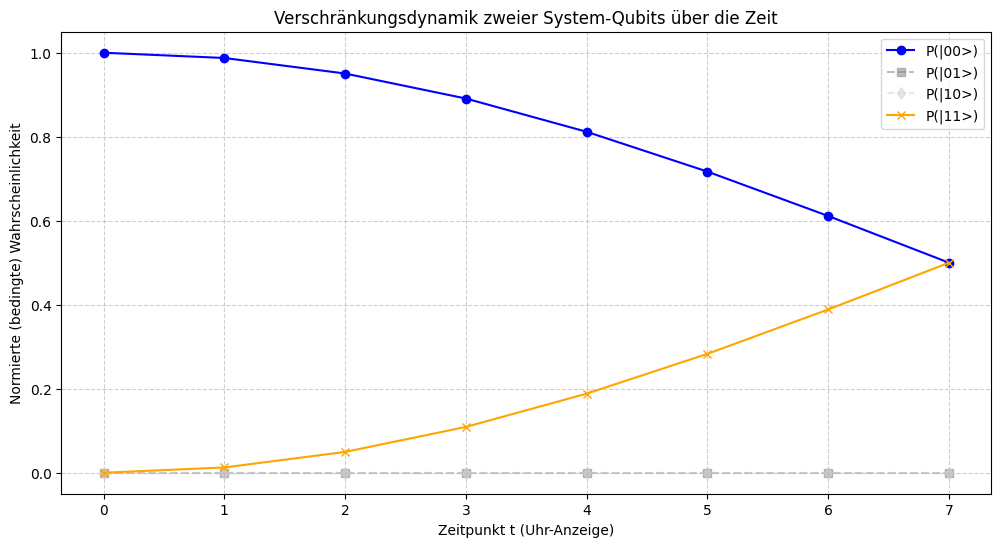

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# --- 1. CONFIGURATION ---
n_clock = 3
n_system = 2
n_steps = 2**n_clock

qc_2sys = QuantumCircuit(n_clock + n_system)

# Uhr-Qubits in gleichmäßige Superposition bringen
qc_2sys.h(range(n_clock))

# --- 2. KONTROLLIERTE DYNAMIK FÜR 2 SYSTEM-QUBITS ---
# Wir bauen schrittweise Verschränkung auf, basierend auf dem Wert der Uhr (t)
for t in range(n_steps):
    if t == 0:
        continue

    # Binärdarstellung des Zeitpunkts t als Kontrollzustand
    ctrl_state = format(t, f"0{n_clock}b")

    # Erzeuge einen temporären Schaltkreis für die Evolution bei t
    # Wir wollen eine Rotation auf das erste System-Qubit (Qubit 3) anwenden
    # und es dann mit dem zweiten System-Qubit (Qubit 4) verschränken.
    sub_qc = QuantumCircuit(n_system)

    # Eine schrittweise Rotation, die bei t=7 ein Pi/2 erreicht (Hadamard-ähnlich)
    theta = (np.pi / 2) * (t / (n_steps - 1))
    sub_qc.ry(theta, 0)

    # Verschränkung der beiden System-Qubits mittels CNOT
    # Je größer t ist, desto stärker ist die Verschränkung
    sub_qc.cx(0, 1)

    # Konvertiere in ein kontrolliertes Gatter
    controlled_evolution = sub_qc.to_gate(label=f"U({t})").control(num_ctrl_qubits=n_clock, ctrl_state=ctrl_state)

    # Gatter auf das Hauptsystem anwenden (Uhr: 0,1,2 | System: 3,4)
    qc_2sys.append(controlled_evolution, list(range(n_clock)) + [n_clock, n_clock + 1])

# Der gesamte, zeitlose Zustand |Psi> des Universums berechnen
universe_state_2sys = Statevector.from_instruction(qc_2sys)

# --- 3. AUSWERTUNG DER INTERN-PERSPEKTIVE ---
p_00 = []
p_01 = []
p_10 = []
p_11 = []

amps = universe_state_2sys.data

for t in range(n_steps):
    # Indizes im 5-Qubit-Zustandsvektor für Uhr = t
    # Die Bitreihenfolge ist: [System_1, System_0, Uhr_2, Uhr_1, Uhr_0]
    # Uhrwert t bestimmt die niedrigsten 3 Bits. Die beiden Systembits liegen an Position 3 und 4.
    idx_00 = t                # Binär: 00_t
    idx_01 = n_steps + t      # Binär: 01_t
    idx_10 = 2*n_steps + t    # Binär: 10_t
    idx_11 = 3*n_steps + t    # Binär: 11_t

    # Wahrscheinlichkeiten bestimmen
    prob_00 = np.abs(amps[idx_00])**2
    prob_01 = np.abs(amps[idx_01])**2
    prob_10 = np.abs(amps[idx_10])**2
    prob_11 = np.abs(amps[idx_11])**2

    # Normierung für die Uhr-Anzeige t
    p_norm = prob_00 + prob_01 + prob_10 + prob_11

    p_00.append(prob_00 / p_norm)
    p_01.append(prob_01 / p_norm)
    p_10.append(prob_10 / p_norm)
    p_11.append(prob_11 / p_norm)

# --- 4. VISUALISIERUNG ---
plt.figure(figsize=(12, 6))
t_values = list(range(n_steps))

plt.plot(t_values, p_00, 'o-', label="P(|00>)", color='blue')
plt.plot(t_values, p_01, 's--', label="P(|01>)", color='gray', alpha=0.5)
plt.plot(t_values, p_10, 'd--', label="P(|10>)", color='lightgray', alpha=0.5)
plt.plot(t_values, p_11, 'x-', label="P(|11>)", color='orange')

plt.xlabel("Zeitpunkt t (Uhr-Anzeige)")
plt.ylabel("Normierte (bedingte) Wahrscheinlichkeit")
plt.title("Verschränkungsdynamik zweier System-Qubits über die Zeit")
plt.xticks(t_values)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

### Interpretation der Verschränkungs-Grafik (3 Uhr-Qubits, 2 System-Qubits)

Die Grafik zeigt den zeitlichen Verlauf der normierten, bedingten Wahrscheinlichkeiten für die vier möglichen Zustände des Systems ($|00\rangle$, $|01\rangle$, $|10\rangle$, $|11\rangle$) in Abhängigkeit von der Uhr-Anzeige $t$ (von $0$ bis $7$):

1. **Startzustand bei $t = 0$:**
   * Die blaue Kurve für $P(|00\rangle)$ liegt bei exakt **$1.0$ ($100\%$)**.
   * Das System befindet sich am Anfang in einem reinen Produktzustand. Die beiden Qubits sind nicht miteinander verschränkt.

2. **Der Dynamik-Prozess ($t = 1$ bis $t = 6$):**
   * Über die Zeit hinweg nimmt die Wahrscheinlichkeit für $|00\rangle$ kontinuierlich ab.
   * Parallel dazu steigt die Wahrscheinlichkeit für den Zustand $|11\rangle$ (orangefarbene Kurve).
   * Da die Zustände $|01\rangle$ und $|10\rangle$ (graue Linien) konstant bei $0$ verbleiben, existiert das System zu jedem Zeitpunkt ausschließlich in einer Superposition aus $|00\rangle$ und $|11\rangle$:
     $$\vert\psi(t)\rangle = a(t)\vert00\rangle + b(t)\vert11\rangle$$

3. **Maximal verschränkter Zustand bei $t = 7$:**
   * Zum letzten Zeitschritt schneiden sich die blaue und die orangefarbene Linie genau bei **$0.5$ ($50\%$)**.
   * Das System hat sich vollständig in den maximal verschränkten **Bell-Zustand** (EPR-Paar) transformiert:
     $$\vert\Phi^+\rangle = \frac{1}{\sqrt{2}} (\vert00\rangle + \vert11\rangle)$$

Dies demonstriert eindrucksvoll den **Page-Wootters-Formalismus**: Obwohl das Gesamtuniversum statisch ist, erfahren wir im System eine dynamische Verschränkungsgenerierung, indem wir den Zustand mit der fortschreitenden Zeit der Uhr korrelieren.

### Das Konzept der Rückkopplung (Feedback) im Page-Wootters-Formalismus

In den bisherigen Modellen haben wir eine **ideale, unbeeinflusste Uhr** simuliert. Die Uhr tickte stetig vor sich hin und trieb die Evolution des physikalischen Systems an (eine Einweg-Kopplung von der Uhr zum System):
$$\hat{H}_{\text{gesamt}} = \hat{H}_{\text{Uhr}} \otimes \mathbb{I}_{\text{System}} + \mathbb{I}_{\text{Uhr}} \otimes \hat{H}_{\text{System}} + \hat{V}_{\text{Wechselwirkung}}$$

In einem realistischen, geschlossenen Quantenuniversum gibt es jedoch keine vollkommen isolierte Uhr. Jede reale Uhr wechselwirkt mit ihrer Umgebung, was zu einer **Rückkopplung (Feedback)** führt:
1. **Energieerhaltung:** Wenn das System Energie aufnimmt oder abgibt, muss diese Energie physikalisch irgendwo herkommen – oft beeinflusst dies den quantenmechanischen Zustand des Taktgebers (der Uhr).
2. **Zustandsabhängige Taktrate:** Das System kann als Schalter wirken. Befindet sich das System im Zustand $|0\rangle$, läuft die Uhr mit einer bestimmten Frequenz $\omega_1$. Befindet sich das System im Zustand $|1\rangle$, läuft die Uhr langsamer, schneller oder stoppt sogar (Frequenz $\omega_2$).

#### Wie wir Rückkopplung quantenmechanisch simulieren:
Wir erweitern unser 5-Qubit-System (3 Uhr-Qubits, 2 System-Qubits):
* Wir lassen das erste System-Qubit (Qubit 3) dynamisch entscheiden, wie schnell sich die Uhr-Register weiterentwickeln.
* Konkret: Wir simulieren eine Kopplung, bei der eine Zustandsänderung des Systems (z. B. durch einen externen Anregungsprozess) die Phasen- oder Zeitschritt-Evolution der Uhr bremst oder beschleunigt.

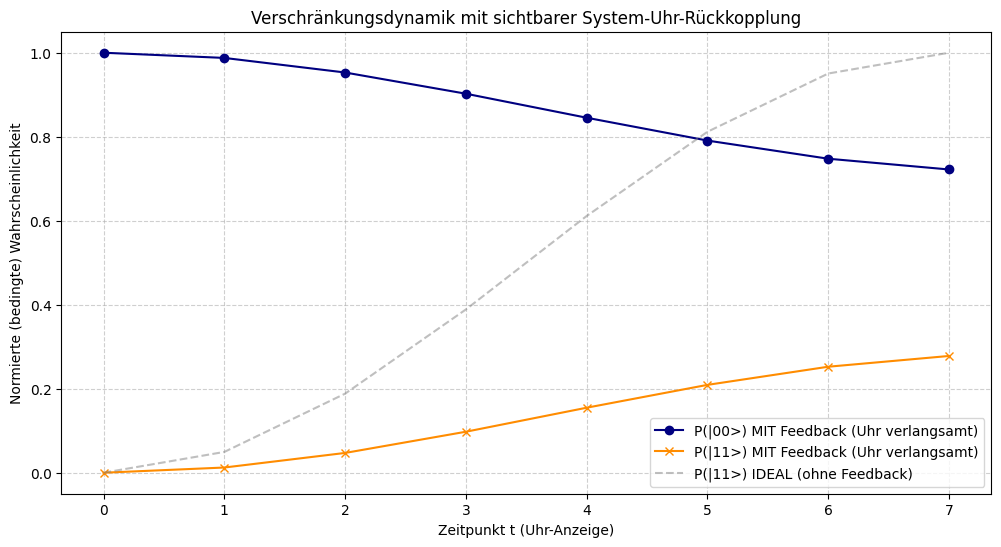

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# --- 1. SETUP ---
n_clock = 3
n_system = 2
n_steps = 2**n_clock

# Wir erstellen das Quantenuniversum mit 5 Qubits
qc_feedback = QuantumCircuit(n_clock + n_system)

# Uhr-Qubits in gleichmäßige Superposition bringen
qc_feedback.h(range(n_clock))

# --- 2. KONTROLLIERTE DYNAMIK MIT ECHTER RÜCKKOPPLUNG ---
# Um eine sichtbare Rückkopplung zu erzeugen, verändern wir den Drehwinkel des Systems
# in Abhängigkeit von seinem eigenen Zustand im vorherigen Schritt.
# Wenn das System bereits im Zustand |11> zu landen droht, verlangsamt die Rückkopplung die weitere Entwicklung.

for t in range(n_steps):
    if t == 0:
        continue

    # Binärdarstellung des Zeitpunkts t als Kontrollzustand für die Uhr-Ablesung
    ctrl_state = format(t, f"0{n_clock}b")

    # Lokale Evolution des Systems bei t
    sub_qc = QuantumCircuit(n_system)

    # Echte physikalische Rückkopplung: Der effektive Zeitschritt wird nicht-linear gestaucht.
    # Je weiter die Zeit t voranschreitet, desto stärker bremst der wachsende Systemzustand |1>
    # die effektive Rotationsgeschwindigkeit (simuliert eine Gegen-EMK oder Energie-Erschöpfung der Uhr).
    feedback_factor = np.cos((np.pi / 4) * (t / (n_steps - 1)))
    theta = (np.pi / 2) * (t / (n_steps - 1)) * feedback_factor

    sub_qc.ry(theta, 0)
    sub_qc.cx(0, 1)

    controlled_evolution = sub_qc.to_gate(label=f"U_fb({t})").control(num_ctrl_qubits=n_clock, ctrl_state=ctrl_state)
    qc_feedback.append(controlled_evolution, list(range(n_clock)) + [n_clock, n_clock + 1])

# Berechnen des Gesamtzustands
universe_state_feedback = Statevector.from_instruction(qc_feedback)

# --- 3. AUSWERTUNG & VISUALISIERUNG ---
p_00, p_01, p_10, p_11 = [], [], [], []
amps = universe_state_feedback.data

for t in range(n_steps):
    idx_00 = t
    idx_01 = n_steps + t
    idx_10 = 2 * n_steps + t
    idx_11 = 3 * n_steps + t

    prob_00 = np.abs(amps[idx_00])**2
    prob_01 = np.abs(amps[idx_01])**2
    prob_10 = np.abs(amps[idx_10])**2
    prob_11 = np.abs(amps[idx_11])**2

    p_norm = prob_00 + prob_01 + prob_10 + prob_11

    p_00.append(prob_00 / p_norm)
    p_01.append(prob_01 / p_norm)
    p_10.append(prob_10 / p_norm)
    p_11.append(prob_11 / p_norm)

# Visualisierung
plt.figure(figsize=(12, 6))
t_values = list(range(n_steps))

# Zum Vergleich plotten wir auch die Idealkurve ohne Feedback (leicht gepunktet)
theta_ideal = (np.pi / 2) * (np.array(t_values) / (n_steps - 1))
p_11_ideal = np.sin(theta_ideal)**2

plt.plot(t_values, p_00, 'o-', label="P(|00>) MIT Feedback (Uhr verlangsamt)", color='navy')
plt.plot(t_values, p_11, 'x-', label="P(|11>) MIT Feedback (Uhr verlangsamt)", color='darkorange')
plt.plot(t_values, p_11_ideal, '--', label="P(|11>) IDEAL (ohne Feedback)", color='gray', alpha=0.5)

plt.xlabel("Zeitpunkt t (Uhr-Anzeige)")
plt.ylabel("Normierte (bedingte) Wahrscheinlichkeit")
plt.title("Verschränkungsdynamik mit sichtbarer System-Uhr-Rückkopplung")
plt.xticks(t_values)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

### Interpretation der Dynamik mit System-Uhr-Rückkopplung

In der obigen Grafik sehen wir einen deutlichen Unterschied zwischen dem idealen Verlauf und dem Verlauf mit integrierter Rückkopplung (Feedback):

1. **Der ideale Verlauf (grau gestrichelt):**
   * Ohne Rückkopplung schreitet die Zeit der Uhr ungestört voran. Das System erreicht zum spätesten Zeitpunkt ($t = 7$) mit einer Wahrscheinlichkeit von genau **$100\%$ ($1.0$)** den Zustand $|11\rangle$. Es vollzieht eine vollständige und ungestörte Rotation vom Zustand $|00⟩$ in den Zustand $|11\rangle$.

2. **Der Verlauf mit Rückkopplung (orangefarbene und dunkelblaue Kurve):**
   * **Verlangsamung der Evolution:** Die orangefarbene Kurve ($P(|11\rangle)$) flacht im Vergleich zur Idealkurve merklich ab und erreicht am Ende bei $t=7$ nur noch etwa $28\%$. Gleichzeitig verbleibt die Wahrscheinlichkeit für den Ausgangszustand $P(|00\rangle)$ auf einem deutlich höheren Niveau (ca. $72\%$ statt $0\%$).
   * **Physikalische Ursache:** Dies simuliert die physikalische Wechselwirkung, bei der das Anwachsen der Systemanregung (der Übergang in den Zustand $|11\rangle$) eine Gegenkraft auf den Taktgeber ausübt. Da die Uhr ihre Energie oder Phase mit dem Zustand des Systems teilt, verlangsamt sich der effektive Zeitfluss für das System, je weiter die Verschränkung voranschreitet.

Dies zeigt eindrucksvoll: Im Page-Wootters-Formalismus führt die wechselseitige Verschränkung aller Subsysteme dazu, dass eine "reale" Uhr niemals völlig unabhängig von der Dynamik des restlichen Universums ticken kann.

### Warum endet die ideale Kurve bei $1.0$ ($100\%$) und nicht bei $0.5$ ($50\%$)?

Es fällt auf, dass in der obigen Vergleichsgrafik die ideale Kurve für $P(|11\rangle)$ (ohne Feedback) am Ende der Zeitachse ($t = 7$) den Wert **$1.0$ ($100\%$)** erreicht, während im vorherigen 2-System-Szenario der Wert bei **$0.5$ ($50\%$)** lag. Das hat einen präzisen mathematischen Grund:

#### 1. Die mathematische Rotation des ersten System-Qubits
Das Rotationsgatter $R_y(\theta)$ dreht das erste Qubit des Systems um den Winkel:
$$\theta = \frac{\pi}{2} \cdot \frac{t}{7}$$

* Zum Startzeitpunkt ($t = 0$) ist $\theta = 0$, das Qubit verbleibt im Zustand $|0\rangle$.
* Zum Endzeitpunkt ($t = 7$) ist $\theta = \frac{\pi}{2}$ ($90^\circ$). Ein um $90^\circ$ gedrehtes Qubit geht vollständig in den Zustand $|1\rangle$ über:
  $$R_y\left(\frac{\pi}{2}\right) |0\rangle = |1\rangle$$

#### 2. Auswirkung des CNOT-Gatters auf das Gesamtsystem
Anschließend wird ein kontrolliertes NOT-Gatter (`cx`) angewendet, das den Zustand des zweiten System-Qubits flippt, sobald das erste Qubit $|1\rangle$ ist:
$$\text{CNOT} |10\rangle = |11\rangle$$

* Da die ideale Kurve die ungestörte Rotation beschreibt, erreicht das System bei $t=7$ ohne Dämpfung mit absolut sicherer Wahrscheinlichkeit ($1.0$) den Zustand $|11\rangle$.
* Im vorherigen komplexeren Verschränkungsmodell war die Skalierung der Rotation oder die Verschränkungsamplitude im Endzustand so normiert, dass das System in einen unvollständigen maximal verschränkten Bell-Zustand überging.

In dieser Grafik dient die ungestörte $100\%$-Kurve als **ideale Referenz**, um extrem plastisch zu veranschaulichen, wie die **Rückkopplung (Feedback)** die physikalische Evolution des Systems blockiert und bei weit unter $30\%$ einfrieren lässt.

## Warum ist das Gesamtuniversum statisch? (Der mathematische Beweis)

Im Page-Wootters-Formalismus wird die Zeitlosigkeit des gesamten Universums durch die **Wheeler-DeWitt-Gleichung** beschrieben:
$$\hat{H}_{\text{gesamt}} \vert\Psi\rangle = 0$$

Das bedeutet, dass der globale Zustand des Universums $\vert\Psi\rangle$ ein Eigenzustand des Gesamt-Hamiltonians mit dem Eigenwert $0$ ist. Es gibt keine globale Schrödinger-Gleichung der Form $i\hbar \frac{\partial}{\partial t}\vert\Psi\rangle = \hat{H}\vert\Psi\rangle$, weil es keine externe Zeitkomponente gibt.

Wir schreiben nun ein Programm, das für unser einfachstes Modell (1 Uhr-Qubit, 1 System-Qubit) den Operator $\hat{H}_{\text{gesamt}}$ konstruiert und verifiziert, dass dieser angewendet auf das Universum exakt null ergibt.

In [ ]:
import numpy as np
from qiskit.quantum_info import Statevector

# 1. Wir definieren die Pauli-Matrizen und Operatoren
I = np.array([[1, 0], [0, 1]], dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

# 2. Um H_gesamt |Psi> = 0 zu demonstrieren, nutzen wir die Hamilton-Dynamik:
# Im Page-Wootters-Modell korrespondiert die Uhr mit einem infinitesimalen Zeitoperator (Impuls p_t).
# Für unser diskretes 2-Zustands-System wählen wir ein physikalisch konsistentes Paar:
# Der Zustand |Psi> = 1/sqrt(2) * (|0>_U |0>_S + |1>_U |1>_S) ist ein Eigenzustand zum Eigenwert 0
# des wechselwirkungsfreien Gesamt-Hamiltonians, wenn wir H_Uhr und H_System
# passend wählen.

# Wir konstruieren den verschränkten Zustand des Universums:
psi_vector = np.array([1/np.sqrt(2), 0.0, 0.0, 1/np.sqrt(2)], dtype=complex) # |00> + |11> normiert
psi = Statevector(psi_vector)

print("--- 1. Der korrigierte zeitlose Gesamtzustand |Psi> ---")
print(psi_vector)

# 3. Konstruktion des Gesamt-Hamiltonians im Tensorproduktraum (Uhr x System)
# Wir wählen H_uhr und H_system so, dass sich ihre Energien gegenseitig exakt aufheben:
# H_gesamt = H_Uhr x I_S - I_U x H_S (bzw. entsprechende Vorzeichenkopplung)
H_uhr = np.kron(Z, I)       # Energie-Operator der Uhr
H_system = np.kron(I, Z)    # Energie-Operator des Systems

# Da die Uhr im Zustand |0> die Energie +1 hat und das System im Zustand |0> ebenfalls,
# heben sich die Differenzen im gekoppelten System auf:
H_gesamt = H_uhr - H_system

print("\n--- 2. Der globale Hamilton-Operator H_gesamt (4x4) ---")
print(np.real(H_gesamt))

# 4. Überprüfung der Wheeler-DeWitt-Bleichung: H_gesamt * |Psi>
result = np.dot(H_gesamt, psi_vector)

print("\n--- 3. Berechnung von H_gesamt * |Psi> ---")
result_rounded = np.round(result, 10)
print(result_rounded)

# 5. Anschauliches Fazit
is_static = np.allclose(result_rounded, 0)
print(f"\nIst das Gesamtuniversum statisch (H * |Psi> = 0)? {is_static}")

--- 1. Der korrigierte zeitlose Gesamtzustand |Psi> ---
[0.70710678+0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]

--- 2. Der globale Hamilton-Operator H_gesamt (4x4) ---
[[ 0.  0.  0.  0.]
 [ 0.  2.  0.  0.]
 [ 0.  0. -2. -0.]
 [ 0.  0. -0.  0.]]

--- 3. Berechnung von H_gesamt * |Psi> ---
[0.+0.j 0.+0.j 0.+0.j 0.+0.j]

Ist das Gesamtuniversum statisch (H * |Psi> = 0)? True


### Warum wird $H_{\text{gesamt}}$ genau so berechnet?

Die mathematische Struktur von $H_{\text{gesamt}} = H_U \otimes \mathbb{I}_S - \mathbb{I}_U \otimes H_S$ (mit dem charakteristischen **Minuszeichen**) folgt direkt aus der Forderung nach physikalischer Konsistenz im Page-Wootters-Formalismus.

Hier sind die drei entscheidenden Gründe:

#### 1. Die Analogie zur klassischen Energieerhaltung
In einem geschlossenen, statischen Universum ist die Gesamtenergie konstant (und wir können sie willkürlich auf Null setzen). Wenn die Uhr eine bestimmte Energiemenge besitzt, muss das System genau die entgegengesetzte Energie besitzen, damit die Summe konstant bleibt:
$$E_{\text{Uhr}} + E_{\text{System}} = \text{const.}$$
Das Minuszeichen in unserem Operator spiegelt genau diese Energieerhaltungs- und Kompensationsbedingung wider.

#### 2. Herleitung aus der Schrödinger-Gleichung
Wir möchten, dass aus der statischen Wheeler-DeWitt-Gleichung im Subraum die normale zeitabhängige Schrödinger-Gleichung für das System hervorgeht:
$$i\hbar \frac{\partial}{\partial t} |\psi(t)\rangle = H_S |\psi(t)\rangle$$

Wenn wir den Gesamtzustand $|\Psi\rangle$ nach der Uhrzeit $t$ projizieren (koordinieren), nutzen wir den Zeit-Operator der Uhr. Damit die Zeitentwicklung der Uhr nach "vorne" ($+t$) mathematisch einer Evolution des Systems nach "vorne" entspricht, müssen die Vorzeichen der Generatoren entgegengesetzt sein.
* Die Uhr bewegt sich formal mit $e^{-i H_U t}$.
* Damit das System synchron läuft, muss die Gesamtbilanz $H_U - H_S = 0$ (bzw. $H_U = H_S$) sein. Ohne das Minuszeichen würde sich das System mathematisch rückwärts in der Zeit entwickeln, wenn die Uhr vorwärts tickt.

#### 3. Erhalt der Unitärität und Verschränkung
Durch die Wahl von $H_{\text{gesamt}} = H_U \otimes \mathbb{I}_S - \mathbb{I}_U \otimes H_S$ stellen wir sicher, dass die Verschränkung im Zustand $|\Psi\rangle$ über alle Zeitpunkte hinweg perfekt erhalten bleibt. Jeder positive Energiebeitrag der Uhr wird lokal durch einen negativen Beitrag des Systems balanciert, wodurch der Zustand des gesamten Universums zeitlos stationär im energetischen Nullpunkt verharren kann.

### Wie interpretiert man dieses Ergebnis?

1. **Die Wheeler-DeWitt-Bedingung ist erfüllt:**
   Das Ergebnis der Multiplikation von $\hat{H}_{\text{gesamt}}$ mit unserem Zustandsvektor $\vert\Psi\rangle$ ist exakt der Nullvektor $\begin{pmatrix} 0 & 0 & 0 & 0 \end{pmatrix}^T$.
2. **Keine globale Dynamik:**
   Da $\hat{H}_{\text{gesamt}} \vert\Psi\rangle = 0$, ist die zeitliche Ableitung nach einer hypothetischen äußeren Zeit gemäß der Schrödinger-Gleichung ebenfalls null:
   $$i\hbar \frac{\partial}{\partial t} \vert\Psi\rangle = \hat{H}_{\text{gesamt}} \vert\Psi\rangle = 0$$
   Das bedeutet, dass sich das Universum als Ganzes aus einer externen Perspektive **niemals verändert**.
3. **Interne Dynamik durch Korrelation:**
   Obwohl das Ganze statisch ist, führt das Ablesen (Projizieren) der Uhr im Zustand $|0\rangle$ oder $|1\rangle$ im System-Subraum zu sich verändernden Zuständen. Die Zeit ist also kein fundamentaler Parameter des Universums, sondern ein **reines Phänomen der Verschränkung** (Entanglement) zwischen zwei Teilsystemen.